# Board Games!!!

The goal of this is to guess wether a game is complex or simple based on other variables. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_fscore_support


In [2]:
db = pd.read_csv('data/bgg_dataset.csv', sep=';', decimal=',')
db.head()

,ID,Name,Year Published,Min Players,Max Players,Play Time,Min Age,Users Rated,Rating Average,BGG Rank,Complexity Average,Owned Users,Mechanics,Domains
0,174430.0,Gloomhaven,2017.0,1,4,120,14,42055,8.79,1,3.86,68323.0,"Action Queue, Action Retrieval, Campaign / Bat...","Strategy Games, Thematic Games"
1,161936.0,Pandemic Legacy: Season 1,2015.0,2,4,60,13,41643,8.61,2,2.84,65294.0,"Action Points, Cooperative Game, Hand Manageme...","Strategy Games, Thematic Games"
2,224517.0,Brass: Birmingham,2018.0,2,4,120,14,19217,8.66,3,3.91,28785.0,"Hand Management, Income, Loans, Market, Networ...",Strategy Games
3,167791.0,Terraforming Mars,2016.0,1,5,120,12,64864,8.43,4,3.24,87099.0,"Card Drafting, Drafting, End Game Bonuses, Han...",Strategy Games
4,233078.0,Twilight Imperium: Fourth Edition,2017.0,3,6,480,14,13468,8.70,5,4.22,16831.0,"Action Drafting, Area Majority / Influence, Ar...","Strategy Games, Thematic Games"


In [25]:
# Summary statistics for key numerical features and target
summary_cols = candidate_features + ['Complexity Average']

summary_stats = analysis_df[summary_cols].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']]
summary_stats['median'] = summary_stats.pop('50%')
summary_stats['missing_values'] = analysis_df[summary_cols].isnull().sum()

# Round for clean presentation
summary_stats = summary_stats.round(2)

print("=" * 75)
print("FEATURE SUMMARY STATISTICS (Min, Max, Mean, Median, Std)")
print("=" * 75)
display(summary_stats)

FEATURE SUMMARY STATISTICS (Min, Max, Mean, Median, Std)


,count,mean,std,min,max,median,missing_values
Year Published,20108.0,2005.82,17.11,1700.00,2022.00,2011.00,0
Min Players,20108.0,2.02,0.69,0.00,10.00,2.00,0
Max Players,20108.0,5.66,15.27,0.00,999.00,4.00,0
Play Time,20108.0,91.97,548.58,0.00,60000.00,45.00,0
Min Age,20108.0,9.64,3.62,0.00,25.00,10.00,0
Users Rated,20108.0,844.03,3522.23,30.00,102214.00,121.00,0
Rating Average,20108.0,6.41,0.93,1.05,9.54,6.43,0
Complexity Average,20108.0,2.00,0.85,0.00,5.00,2.00,0


In [16]:
# 3. Select clean quantitative features and define dual complexity thresholds
candidate_features = [
    'Year Published', 'Min Players', 'Max Players', 
    'Play Time', 'Min Age', 'Users Rated', 'Rating Average'
]

# Drop NaNs across candidate features and target metric
analysis_df = db[candidate_features + ['Complexity Average']].dropna().copy()

# Filter out ancient/outlier years
analysis_df = analysis_df[analysis_df['Year Published'] >= 1700]

# Define both classification thresholds
analysis_df['is_complex_20'] = (analysis_df['Complexity Average'] >= 2.0).astype(int)
analysis_df['is_complex_25'] = (analysis_df['Complexity Average'] >= 2.5).astype(int)

print(f"Remaining rows after cleaning: {len(analysis_df)}")
print("\nClass Balance for Threshold = 2.0:")
print(analysis_df['is_complex_20'].value_counts(normalize=True))
print("\nClass Balance for Threshold = 2.5:")
print(analysis_df['is_complex_25'].value_counts(normalize=True))

Remaining rows after cleaning: 20108

Class Balance for Threshold = 2.0:
is_complex_20
1    0.5
0    0.5
Name: proportion, dtype: float64

Class Balance for Threshold = 2.5:
is_complex_25
0    0.722747
1    0.277253
Name: proportion, dtype: float64


Correlation with is_complex:
is_complex        1.000000
Rating Average    0.435217
Min Age           0.274384
Play Time         0.103748
Users Rated       0.048426
Year Published    0.038413
Max Players      -0.080861
Min Players      -0.163590
Name: is_complex, dtype: float64


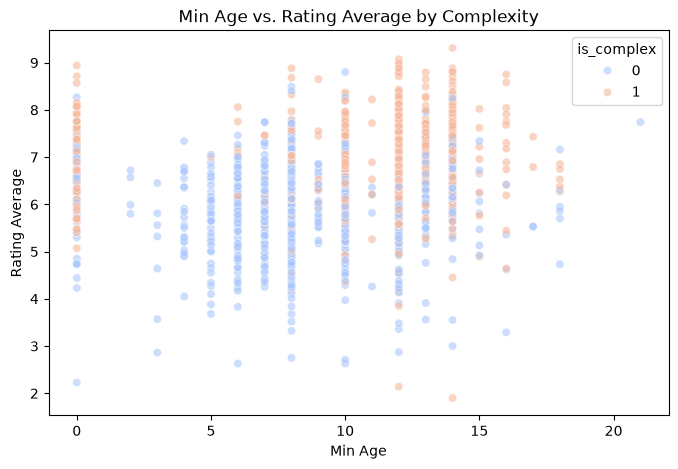

In [4]:
# Compute correlations with the target
corr = analysis_df.corr()['is_complex'].sort_values(ascending=False)
print("Correlation with is_complex:")
print(corr)

# Visualize a key pair of predictive variables (e.g., Min Age vs Play Time or Rating Average)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=analysis_df.sample(min(2000, len(analysis_df)), random_state=42), 
    x='Min Age', 
    y='Rating Average', 
    hue='is_complex', 
    alpha=0.6,
    palette='coolwarm'
)
plt.title("Min Age vs. Rating Average by Complexity")
plt.show()

In [5]:
X = analysis_df[candidate_features]
y = analysis_df['is_complex']

# Split into 80/20 train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

print("--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_lr))

# Model 2: Linear SVM
linear_svm = LinearSVC(dual='auto', max_iter=2000, random_state=42)
linear_svm.fit(X_train_scaled, y_train)
y_pred_svm = linear_svm.predict(X_test_scaled)

print("--- Linear SVM Results ---")
print(classification_report(y_test, y_pred_svm))

--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.77      0.85      0.81      2043
           1       0.83      0.75      0.79      2026

    accuracy                           0.80      4069
   macro avg       0.80      0.80      0.80      4069
weighted avg       0.80      0.80      0.80      4069

--- Linear SVM Results ---
              precision    recall  f1-score   support

           0       0.76      0.82      0.79      2043
           1       0.81      0.74      0.77      2026

    accuracy                           0.78      4069
   macro avg       0.78      0.78      0.78      4069
weighted avg       0.78      0.78      0.78      4069



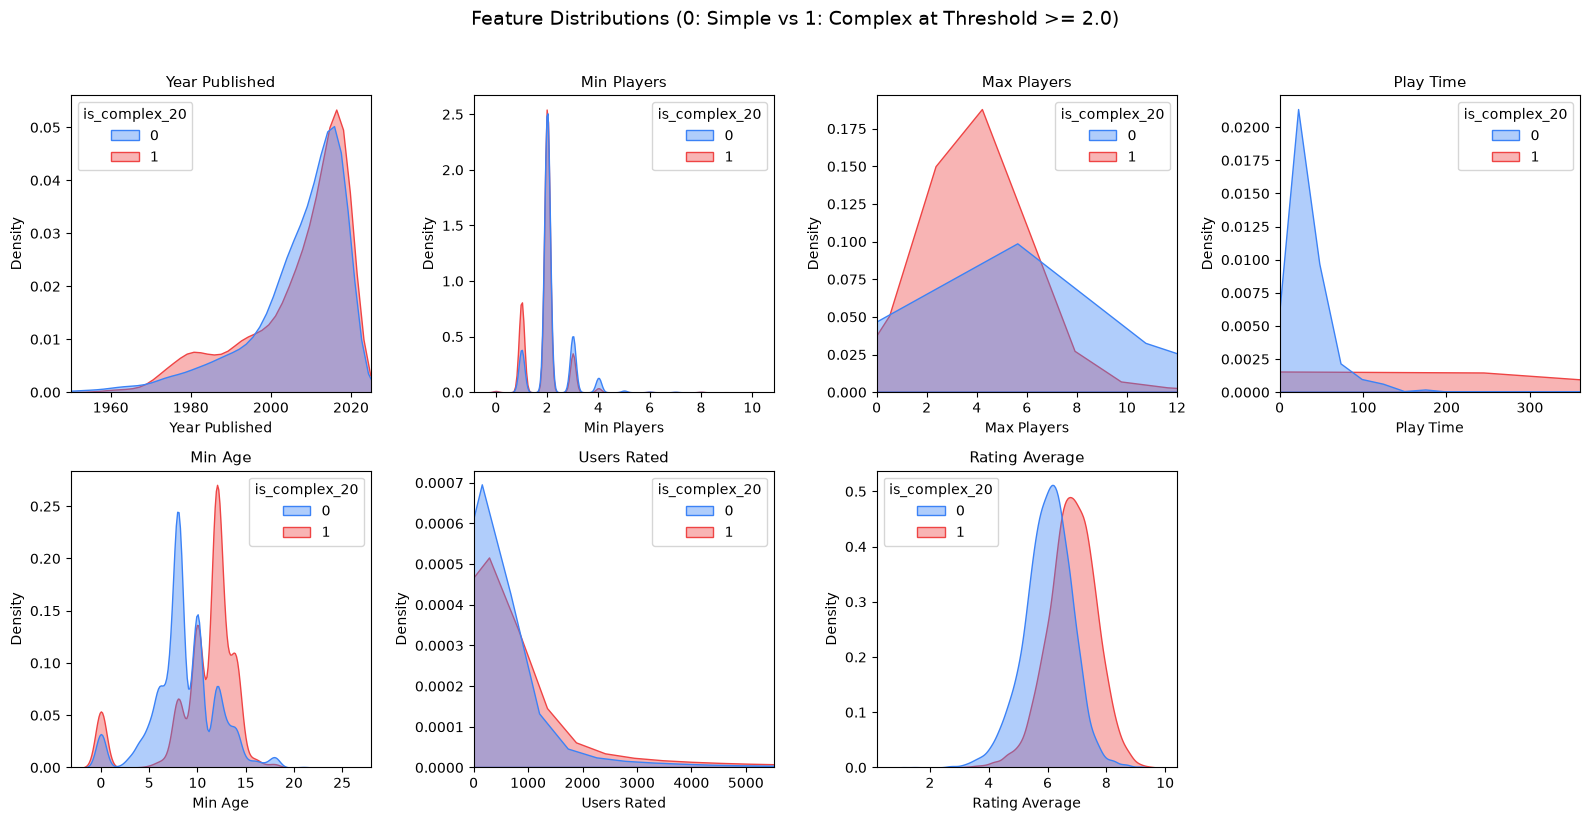

In [21]:
# Feature Distribution by Complexity Class (Showing Primary Threshold 2.0)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for idx, col in enumerate(candidate_features):
    sns.kdeplot(
        data=analysis_df, 
        x=col, 
        hue='is_complex_20', 
        common_norm=False, 
        fill=True, 
        alpha=0.4, 
        palette=['#3b82f6', '#ef4444'], 
        ax=axes[idx]
    )
    
    # Clip extreme display tails with custom lower/upper bounds
    if col in ['Play Time', 'Users Rated', 'Owned Users']:
        upper_limit = analysis_df[col].quantile(0.97)
        axes[idx].set_xlim(0, upper_limit)
    elif col == 'Max Players':
        axes[idx].set_xlim(0, 12)
    elif col == 'Year Published':
        axes[idx].set_xlim(1950, 2025)
        
    axes[idx].set_title(col, fontsize=11)

# Remove the unused 8th subplot in the 2x4 grid
fig.delaxes(axes[7])

plt.suptitle("Feature Distributions (0: Simple vs 1: Complex at Threshold >= 2.0)", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

FINAL RESULTS SUMMARY: MODEL EVALUATION ACROSS THRESHOLDS


,Threshold,Model,Accuracy,Precision (Complex),Recall (Complex),F1-Score (Complex)
0,Threshold 2.0,RBF SVM (balanced),0.8182,0.8490,0.7742,0.8099
1,Threshold 2.0,"Logistic Regression (C=100, balanced)",0.8081,0.8432,0.7568,0.7977
2,Threshold 2.0,Linear SVM (balanced),0.7882,0.8179,0.7414,0.7778
3,Threshold 2.5,RBF SVM (balanced),0.8352,0.6633,0.8233,0.7347
4,Threshold 2.5,"Logistic Regression (C=100, balanced)",0.8307,0.6680,0.7740,0.7171
5,Threshold 2.5,Linear SVM (balanced),0.8247,0.6562,0.7722,0.7095


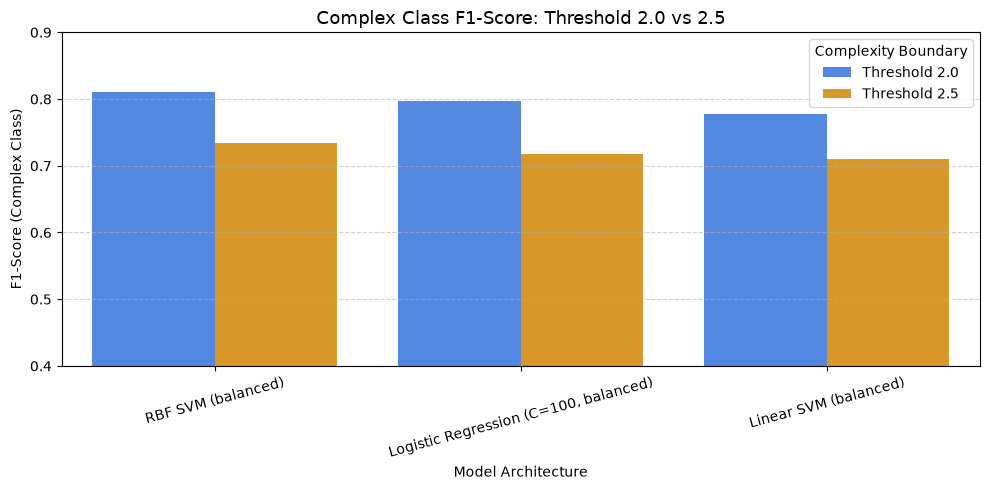

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

threshold_configs = {
    'Threshold 2.0': 'is_complex_20',
    'Threshold 2.5': 'is_complex_25'
}

models = {
    "Logistic Regression (C=100, balanced)": LogisticRegression(C=100, class_weight='balanced', max_iter=1000, random_state=42),
    "Linear SVM (balanced)": LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42),
    "RBF SVM (balanced)": SVC(kernel='rbf', class_weight='balanced', random_state=42)
}

comparison_records = []

for thresh_name, target_col in threshold_configs.items():
    X = analysis_df[candidate_features]
    y = analysis_df[target_col]
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    for model_name, clf in models.items():
        clf.fit(X_train_scaled, y_train)
        preds = clf.predict(X_test_scaled)
        
        acc = accuracy_score(y_test, preds)
        p, r, f1, _ = precision_recall_fscore_support(y_test, preds, average=None)
        
        comparison_records.append({
            'Threshold': thresh_name,
            'Model': model_name,
            'Accuracy': round(acc, 4),
            'Precision (Complex)': round(p[1], 4),
            'Recall (Complex)': round(r[1], 4),
            'F1-Score (Complex)': round(f1[1], 4)
        })

# Compile results table
final_results_df = pd.DataFrame(comparison_records)
final_results_df = final_results_df.sort_values(by=['Threshold', 'F1-Score (Complex)'], ascending=[True, False]).reset_index(drop=True)

print("=" * 75)
print("FINAL RESULTS SUMMARY: MODEL EVALUATION ACROSS THRESHOLDS")
print("=" * 75)
display(final_results_df)

# Visual Comparison of F1 Scores
plt.figure(figsize=(10, 5))
sns.barplot(
    data=final_results_df,
    x='Model',
    y='F1-Score (Complex)',
    hue='Threshold',
    palette=['#3b82f6', '#f59e0b']
)
plt.title("Complex Class F1-Score: Threshold 2.0 vs 2.5", fontsize=13)
plt.ylabel("F1-Score (Complex Class)")
plt.xlabel("Model Architecture")
plt.ylim(0.4, 0.9)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title="Complexity Boundary")
plt.tight_layout()
plt.show()

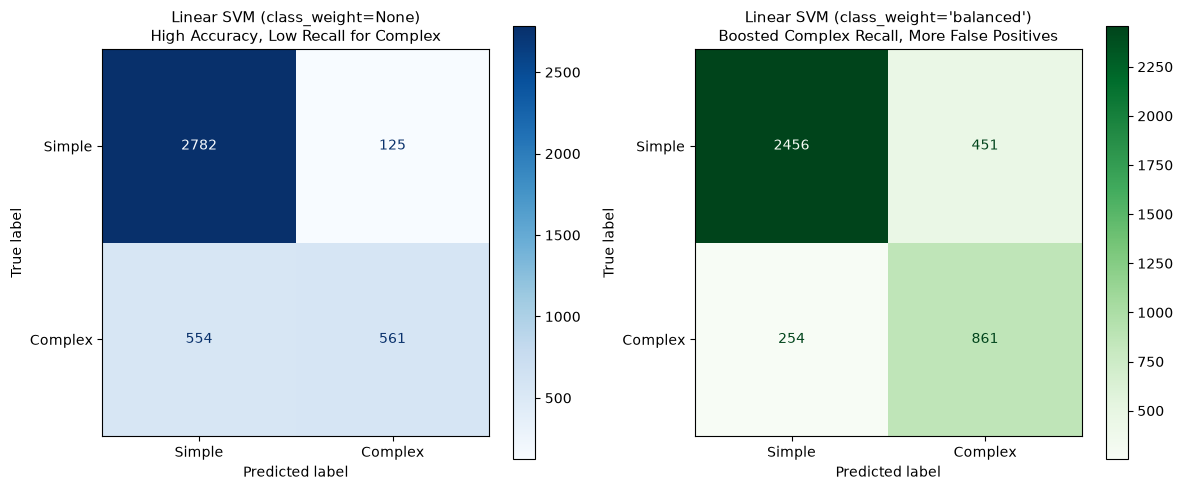

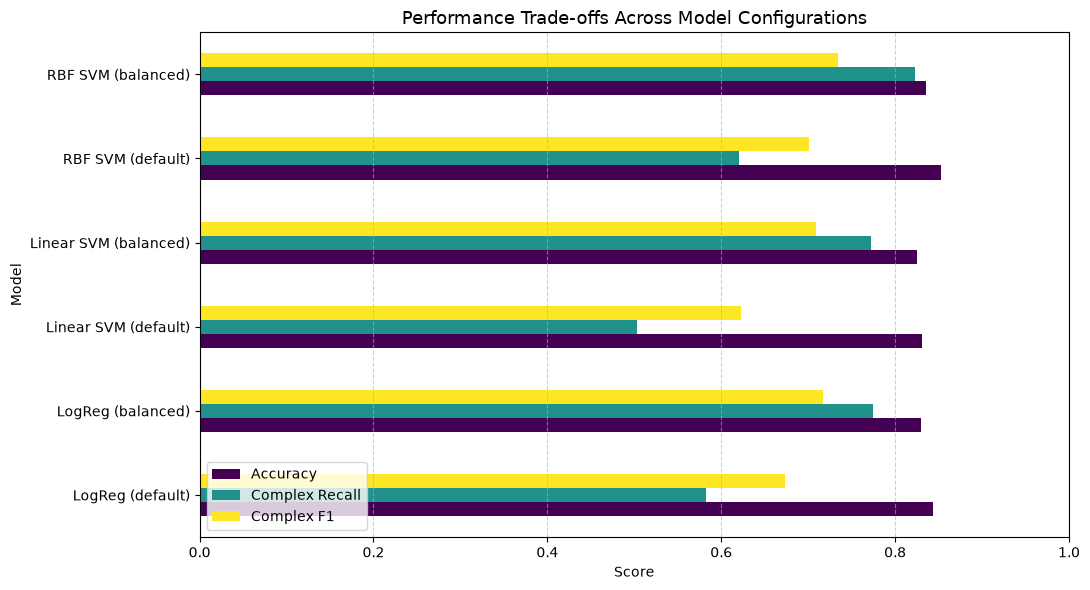

In [22]:
# Train default vs balanced Linear SVMs on the full feature set
svm_unweighted = LinearSVC(dual='auto', class_weight=None, max_iter=2000, random_state=42)
svm_balanced = LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42)

svm_unweighted.fit(X_train_scaled, y_train)
svm_balanced.fit(X_train_scaled, y_train)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(
    svm_unweighted, X_test_scaled, y_test, 
    display_labels=["Simple", "Complex"], 
    cmap="Blues", 
    ax=axes[0]
)
axes[0].set_title("Linear SVM (class_weight=None)\nHigh Accuracy, Low Recall for Complex", fontsize=11)

ConfusionMatrixDisplay.from_estimator(
    svm_balanced, X_test_scaled, y_test, 
    display_labels=["Simple", "Complex"], 
    cmap="Greens", 
    ax=axes[1]
)
axes[1].set_title("Linear SVM (class_weight='balanced')\nBoosted Complex Recall, More False Positives", fontsize=11)

plt.tight_layout()
plt.show()

# Metric summary chart across models
model_suite = {
    "LogReg (default)": LogisticRegression(random_state=42),
    "LogReg (balanced)": LogisticRegression(class_weight='balanced', random_state=42),
    "Linear SVM (default)": LinearSVC(dual='auto', max_iter=2000, random_state=42),
    "Linear SVM (balanced)": LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42),
    "RBF SVM (default)": SVC(kernel='rbf', random_state=42),
    "RBF SVM (balanced)": SVC(kernel='rbf', class_weight='balanced', random_state=42)
}

records = []
for name, clf in model_suite.items():
    clf.fit(X_train_scaled, y_train)
    preds = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    p, r, f, _ = precision_recall_fscore_support(y_test, preds, average=None)
    records.append({
        'Model': name,
        'Accuracy': acc,
        'Complex Precision': p[1],
        'Complex Recall': r[1],
        'Complex F1': f[1]
    })

perf_df = pd.DataFrame(records).set_index('Model')

perf_df[['Accuracy', 'Complex Recall', 'Complex F1']].plot(
    kind='barh', 
    figsize=(11, 6), 
    colormap='viridis'
)
plt.title("Performance Trade-offs Across Model Configurations", fontsize=13)
plt.xlabel("Score")
plt.xlim(0, 1.0)
plt.legend(loc='lower left')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

BOX-ONLY FEATURES EVALUATION SUMMARY (Min/Max Players, Play Time, Age, Year)


,Threshold,Model,Accuracy,Precision (Complex),Recall (Complex),F1-Score (Complex)
0,Threshold 2.0,RBF SVM (balanced),0.8061,0.8234,0.7792,0.8007
1,Threshold 2.0,"Logistic Regression (C=100, balanced)",0.7936,0.8435,0.7210,0.7775
2,Threshold 2.0,Linear SVM (balanced),0.7735,0.8183,0.7031,0.7564
3,Threshold 2.5,"Logistic Regression (C=100, balanced)",0.8274,0.6738,0.7318,0.7016
4,Threshold 2.5,RBF SVM (balanced),0.8021,0.6053,0.8224,0.6973
5,Threshold 2.5,Linear SVM (balanced),0.8192,0.6625,0.7094,0.6851


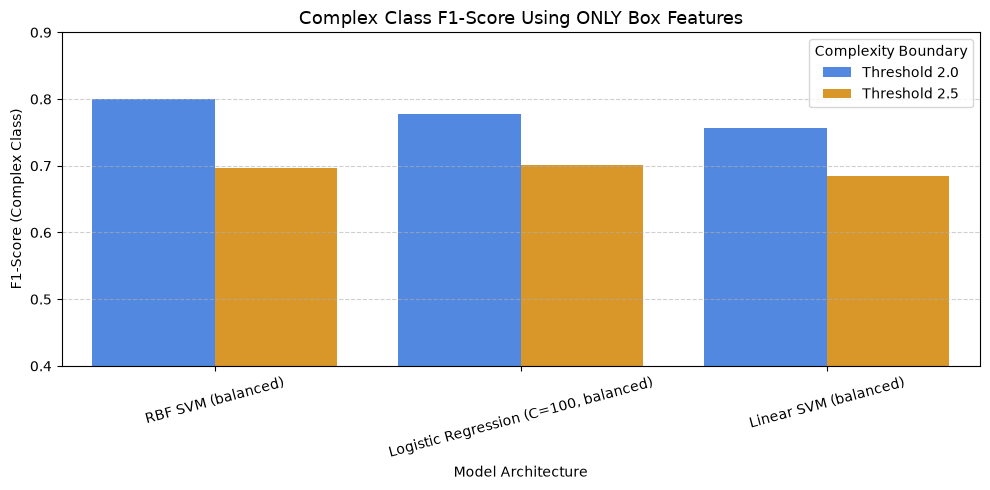

In [24]:
# =============================================================================
# Model Evaluation Using ONLY "Box Variables"
# (Excludes Rating Average, Users Rated, Owned Users, BGG Rank, etc.)
# =============================================================================

box_features = ['Min Players', 'Max Players', 'Play Time', 'Min Age', 'Year Published']

threshold_configs = {
    'Threshold 2.0': 'is_complex_20',
    'Threshold 2.5': 'is_complex_25'
}

models = {
    "Logistic Regression (C=100, balanced)": LogisticRegression(C=100, class_weight='balanced', max_iter=1000, random_state=42),
    "Linear SVM (balanced)": LinearSVC(dual='auto', class_weight='balanced', max_iter=2000, random_state=42),
    "RBF SVM (balanced)": SVC(kernel='rbf', class_weight='balanced', random_state=42)
}

box_comparison_records = []

for thresh_name, target_col in threshold_configs.items():
    X_box = analysis_df[box_features]
    y_box = analysis_df[target_col]
    
    X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
        X_box, y_box, test_size=0.2, random_state=42, stratify=y_box
    )
    
    scaler_b = StandardScaler()
    X_train_b_scaled = scaler_b.fit_transform(X_train_b)
    X_test_b_scaled = scaler_b.transform(X_test_b)
    
    for model_name, clf in models.items():
        clf.fit(X_train_b_scaled, y_train_b)
        preds = clf.predict(X_test_b_scaled)
        
        acc = accuracy_score(y_test_b, preds)
        p, r, f1, _ = precision_recall_fscore_support(y_test_b, preds, average=None)
        
        box_comparison_records.append({
            'Threshold': thresh_name,
            'Model': model_name,
            'Accuracy': round(acc, 4),
            'Precision (Complex)': round(p[1], 4),
            'Recall (Complex)': round(r[1], 4),
            'F1-Score (Complex)': round(f1[1], 4)
        })

# Compile results table
box_results_df = pd.DataFrame(box_comparison_records)
box_results_df = box_results_df.sort_values(
    by=['Threshold', 'F1-Score (Complex)'], ascending=[True, False]
).reset_index(drop=True)

print("=" * 75)
print("BOX-ONLY FEATURES EVALUATION SUMMARY (Min/Max Players, Play Time, Age, Year)")
print("=" * 75)
display(box_results_df)

# Visual Comparison of F1 Scores
plt.figure(figsize=(10, 5))
sns.barplot(
    data=box_results_df, 
    x='Model', 
    y='F1-Score (Complex)', 
    hue='Threshold', 
    palette=['#3b82f6', '#f59e0b']
)
plt.title("Complex Class F1-Score Using ONLY Box Features", fontsize=13)
plt.ylabel("F1-Score (Complex Class)")
plt.xlabel("Model Architecture")
plt.ylim(0.4, 0.9)
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title="Complexity Boundary")
plt.tight_layout()
plt.show()

In [9]:
earthquake = pd.read_csv("data/earthquake_data_tsunami.csv")

In [10]:
display(earthquake.head())
display(earthquake.columns)

,magnitude,cdi,mmi,sig,nst,dmin,gap,depth,latitude,longitude,Year,Month,tsunami
0,7.0,8,7,768,117,0.509,17.0,14.000,-9.7963,159.596,2022,11,1
1,6.9,4,4,735,99,2.229,34.0,25.000,-4.9559,100.738,2022,11,0
2,7.0,3,3,755,147,3.125,18.0,579.000,-20.0508,-178.346,2022,11,1
3,7.3,5,5,833,149,1.865,21.0,37.000,-19.2918,-172.129,2022,11,1
4,6.6,0,2,670,131,4.998,27.0,624.464,-25.5948,178.278,2022,11,1


Index(['magnitude', 'cdi', 'mmi', 'sig', 'nst', 'dmin', 'gap', 'depth',
       'latitude', 'longitude', 'Year', 'Month', 'tsunami'],
      dtype='str')

<Axes: xlabel='longitude', ylabel='latitude'>

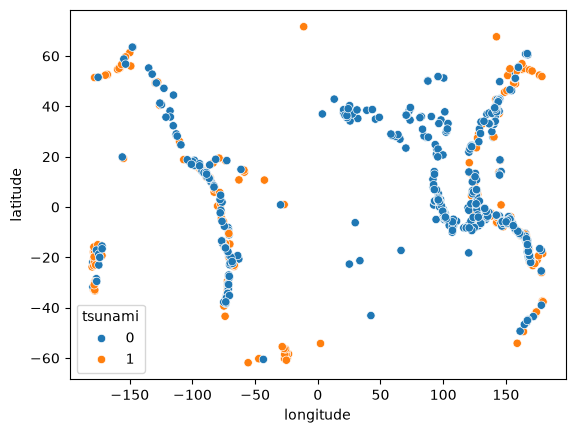

In [11]:
sns.scatterplot(data=earthquake, x="longitude", y="latitude", hue="tsunami")

<Axes: xlabel='Year', ylabel='Density'>

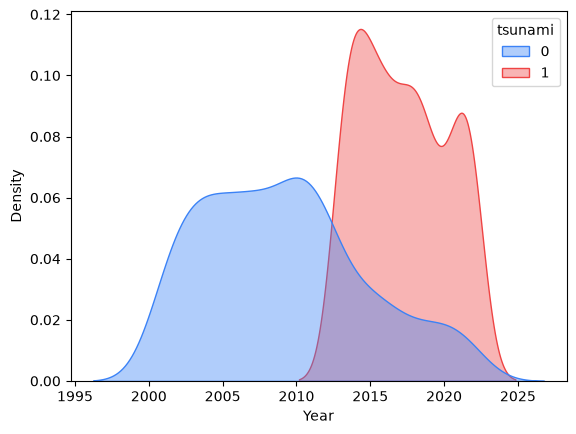

In [12]:
sns.kdeplot(
        data=earthquake, 
        x="Year", 
        hue='tsunami', 
        common_norm=False, 
        fill=True, 
        alpha=0.4, 
        palette=['#3b82f6', '#ef4444']
    )

In [13]:
X = earthquake[["longitude", "latitude", "magnitude", "Year"]]
y = earthquake['tsunami']

# Split into 80/20 train/test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

print("--- Logistic Regression Results ---")
print(classification_report(y_test, y_pred_lr))

# Model 2: Linear SVM
linear_svm = LinearSVC(dual='auto', max_iter=2000, random_state=42)
linear_svm.fit(X_train_scaled, y_train)
y_pred_svm = linear_svm.predict(X_test_scaled)

rbf_svm = SVC(kernel='rbf', gamma='scale', random_state=42, class_weight="balanced")
rbf_svm.fit(X_train_scaled, y_train)
y_pred_rbf_svm = rbf_svm.predict(X_test_scaled)

print("--- Linear SVM Results ---")
print(classification_report(y_test, y_pred_svm))

print("--- Radial SVM Results ---")
print(classification_report(y_test, y_pred_rbf_svm))


--- Logistic Regression Results ---
              precision    recall  f1-score   support

           0       0.81      0.86      0.83        96
           1       0.76      0.67      0.71        61

    accuracy                           0.79       157
   macro avg       0.78      0.77      0.77       157
weighted avg       0.79      0.79      0.79       157

--- Linear SVM Results ---
              precision    recall  f1-score   support

           0       0.82      0.85      0.84        96
           1       0.75      0.70      0.73        61

    accuracy                           0.80       157
   macro avg       0.79      0.78      0.78       157
weighted avg       0.79      0.80      0.79       157

--- Radial SVM Results ---
              precision    recall  f1-score   support

           0       0.97      0.77      0.86        96
           1       0.73      0.97      0.83        61

    accuracy                           0.85       157
   macro avg       0.85      0.87     

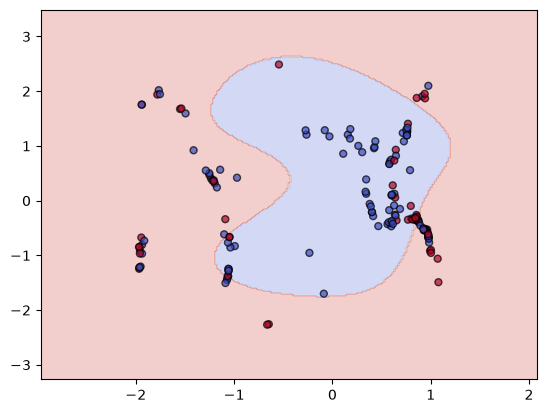

In [14]:
X_te_2d = X_test[["longitude", "latitude"]]
y_te_2d = y_test

X_tr_2d = X_train[["longitude", "latitude"]]


scaler_2d = StandardScaler()
X_tr_2d_scaled = scaler_2d.fit_transform(X_tr_2d)
X_te_2d_scaled = scaler_2d.transform(X_te_2d)

X_vis = X_te_2d_scaled
y_vis = y_te_2d

rbf_svm_2d = SVC()
rbf_svm_2d = SVC(kernel='rbf', gamma='scale', random_state=42, class_weight="balanced")
rbf_svm_2d.fit(X_tr_2d_scaled, y_train)

DecisionBoundaryDisplay.from_estimator(
    rbf_svm_2d, 
    X_vis, 
    response_method="predict",
    cmap="coolwarm", 
    alpha=0.25, 
    grid_resolution=250
)
scatter = plt.scatter(
    X_vis[:, 0], X_vis[:, 1], 
    c=y_vis, 
    cmap="coolwarm", 
    edgecolors='k', 
    s=25, 
    alpha=0.7
)

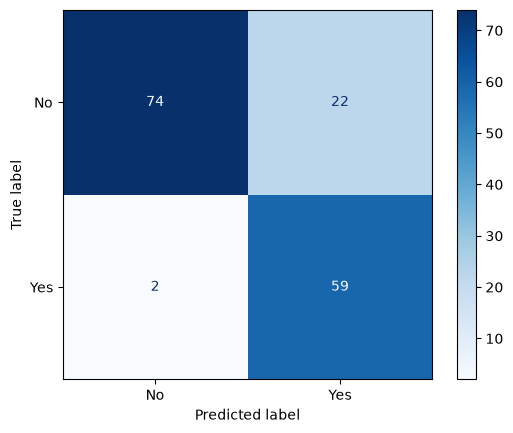

In [15]:
ConfusionMatrixDisplay.from_estimator(
    rbf_svm, X_test_scaled, y_test, 
    display_labels=["No", "Yes"], 
    cmap="Blues"
)